# Numpy-II

## Content

- **Operations on Numpy Arrays**
    - Algebric operations on np arrays with single numbers
    - Operations on two or more np arrays
      - Quiz-1
      - Quiz-2
    - Matrix Multiplication - `matmul()`, `@`, `dot()`


- **Vectorization**
    - `np.vectorize()`


- **Broadcasting**
    - `np.tile()`
    - 2 Questions
    - Quiz-3


- **Array splitting and Merging**
    - Splitting arrays - `split()`, `hsplit()`, `vsplit()`
    - Merging Arrays - `hstack()`, `vstack()`, `concatenate()`
      - Quiz-4 on `hstack()`
      - Quiz-5 on `vstack()`
      - 2 Questions on `concatenate()`
      - Quiz-6


- **Shallow vs Deep Copy**
    - Quiz-7
    
    
- **3D arrays**
  - 1 Question
    
    
- **Use Case: Image Manipulation using Numpy**
    - Opening an Image
    - Details of an image
    - Visualizing RGB Channels
    - Rotating an Image (Transposing a Numpy Array)
    - Saving `ndarray` as Image

In [ ]:
import numpy as np


## Operations on Numpy Arrays

### Algebric operations on np arrays with single numbers

- **Happens on each element of np array**

- Just like multiplication works on each element

- Similarly **addition/subtraction** of np array with a number **works on each element of np array**

In [ ]:
m1 = np.arange(12).reshape(3, 4)
m1 + 2

array([[ 2,  3,  4,  5],
       [ 6,  7,  8,  9],
       [10, 11, 12, 13]])

In [ ]:
m1 = np.arange(12).reshape(3, 4)
m1 * 2

array([[ 0,  2,  4,  6],
       [ 8, 10, 12, 14],
       [16, 18, 20, 22]])

- Similarly, we can do **subtraction**, **raise-to-power**, ...and so on


#### This is similar to mapping in `map()` function

- Each value gets mapped to a new value based on the operation performed

`map(lambda x: x * 2, [...])`


### Algebric operations on two np arrays

In [ ]:
# Corresponding elements of arrays get added
a = np.array([1, 2, 3])
b = np.array([2, 2, 2])
a + b

array([3, 4, 5])

In [ ]:
# Corresponding elements of arrays get multiplied
a * b

array([2, 4, 6])

#### Quiz-1

What will be printed?
```
a = np.array([1,2,3,5,8])
b = np.array([0,3,4,2,1])
c = a + b
c = c*a
print (c[2])
```
**Ans. D**

A : 7

B : 12

C : 10

D : 21

#### Quiz-2
Comparing two arrays
```


a = np.array([0,2,3])
b = np.array([1,3,5])

What'll be the output of a >= b
a. True
b. False
c. Error
d. [False, False, False]

```
Ans: D. (Numpy does element wise comparison)

#### Why did `a*b` not do Matrix Multiplication?

- **Check dimensions of `a` and `b`**


- Both **`a` and `b` are 1D arrays** - shape is **(3,))**


- `a` and `b` are **NOT matrices** - **Dimension is NOT $1\times3$**


- That is why **`a * b`** simply does **element-wise multiplication**


#### Now what if we use multiplication operator on matrices created using numpy?

- Let's create 2 matrices `A` and `B`


- Each of **dimension $3\times4$**

In [ ]:
A = np.arange(12).reshape(3, 4)
A

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

In [ ]:
B = np.arange(12).reshape(3, 4)
B

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

#### Now, Will `A * B` actually do Matrix Multiplication?

Let's see

In [ ]:
A * B

array([[  0,   1,   4,   9],
       [ 16,  25,  36,  49],
       [ 64,  81, 100, 121]])

- It **did NOT do Matrix Multiplication**


- Rather, it **again did element-wise multiplication**


#### Why?

- Check dimensions of matrices `A` and `B`


- **Dimensions of both A and B are $3\times4$**


#### Does this allow Matrix Multiplication?
#### What is the requirement of dimensions of 2 matrices for Matrix Multiplication?

- **Columns of A = Rows of B** (A **Must condition** for Matric Multiplication)


- **If A is $3\times4$, B can be $4\times3$**... or $4\times(Something Else)$


#### Question: What will be dimensions of resulting matrix?

- Rows of A $\times$ Columns of B

- $3\times3$


#### So, lets reshape B to $4\times3$ instead

In [ ]:
B = B.reshape(4, 3)
B

array([[ 0,  1,  2],
       [ 3,  4,  5],
       [ 6,  7,  8],
       [ 9, 10, 11]])

#### Will now the `A * B` give Matrix Multiplication?

Let's see

In [ ]:
A * B

ValueError: operands could not be broadcast together with shapes (3,4) (4,3) 

#### Uh oh! We got an error

- Turns out **`*` operator only does Element-Wise Multiplication of 2 Matrices**

#### For actual Matrix Multiplication, We have a different method/operator

`np.matmul()`

In [ ]:
np.matmul(A, B)

array([[ 42,  48,  54],
       [114, 136, 158],
       [186, 224, 262]])

- **We are getting a $3\times3$ matrix as output**

- So, this is doing Matrix Multiplication

#### There's a direct operator as well for Matrix Multiplication
`@`

In [ ]:
A @ B

array([[ 42,  48,  54],
       [114, 136, 158],
       [186, 224, 262]])

#### Question: What will be the dimensions of Matrix Multiplication `B @ A`?

- $4\times4$

In [ ]:
B @ A

array([[ 20,  23,  26,  29],
       [ 56,  68,  80,  92],
       [ 92, 113, 134, 155],
       [128, 158, 188, 218]])

#### There is another method in np for doing Matrix Multiplication

- `np.dot()`


- It is **NOT the dot product** that we have **in Physics**


- Dot product in Physics is just the element-wise multiplication


- **`np.dot()` performs the actual Matrix Multiplication when both input are 2-D array**

In [ ]:
np.dot(A, B)

array([[ 42,  48,  54],
       [114, 136, 158],
       [186, 224, 262]])

**Other cases of `np.dot()`**
- It performs inner product of vectors when both inputs are 1D array
- It performs multiplication when both input are scalers.


In [ ]:
a= np.array([1,2,3])
b = np.array([1,1,1])


In [ ]:
np.dot(a,b) # 1*1 + 2*1 + 3*1 = 6

6

In [ ]:
np.dot(4,5)

20

#### Now, Let's try multiplication of a mix of matrices and vectors

- So that we are clear on Matrix Multiplication

In [ ]:
A = np.arange(12).reshape(3, 4)  # A is a 3x4 Matrix
A

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

In [ ]:
a = np.array([1, 2, 3])  # a is a 1x3 Vector
print(a)
print(a.shape)

[1 2 3]
(3,)


#### Will `A * a` work?

In [ ]:
A * a

ValueError: operands could not be broadcast together with shapes (3,4) (3,) 

#### Will `a * A` work?

In [ ]:
a * A

ValueError: operands could not be broadcast together with shapes (3,) (3,4) 

#### Why does it not work for either cases?

- Because **`*` operator just performs element-wise multiplication**


- For this, **both A and a should have same shape**


#### However, `A * A` and `a * a` work

In [ ]:
A * A # Multiplied with itself

array([[  0,   1,   4,   9],
       [ 16,  25,  36,  49],
       [ 64,  81, 100, 121]])

In [ ]:
a * a

array([1, 4, 9])

#### Now Let's experiment with `np.matmul()`?

#### Will this work?

In [ ]:
np.matmul(A, a)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 4)

- NO


- `A` is $3\times4$ and `a` is  $1\times3$


- **Columns of `A` $\neq$ Rows of `a`**


#### Will this work?

In [ ]:
np.matmul(a, A)

array([32, 38, 44, 50])

- YES

- **Columns of `a` (3) = Rows of `A` (3)**


- Dimensions of result is $1\times4$


#### Same applies to operator `@` and method `np.dot()`

- `A @ a` will NOT work
- `a @ A` will work


- `np.dot(A, a)` will NOT work
- `np.dot(a, A)` will work


### Conclusion:

- `np.matmul(a, A)`, `a @ A` and `np.dot(a, A)` work


- Because **`a` is implicitly assumed to be a $1\times3$ matrix**


- So, the dimensions of a and A follow the rule for Matrix Maultiplication

## Vectorization

- We have already seen vectorization some time ago

#### Remember doing scaler operations on np arrays?

`A * 2`

#### That's vectorization

- Vectorization helps us to **perform operations directly on Arrays instead of scaler**.

- Operation gets performed on each element of np array

#### Revisiting the example:

In [ ]:
A = np.arange(10)

In [ ]:
A * 2

array([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])

#### `np.vectorize()`

- `np.vectorize()` defines a **vectorized function**


- It **takes numpy arrays as inputs** and **returns a single numpy array or a tuple of numpy arrays**.


- The vectorized function **evaluates element by element of the input arrays** like the python `map` function


#### Let's plot graph for `y = log(x)` (Log function) using` np.vectorize()`

- We will pass in a numpy array, as **it can then take a vector/array/list as input**


- It will **return the vectorized form of `math.log()` function**

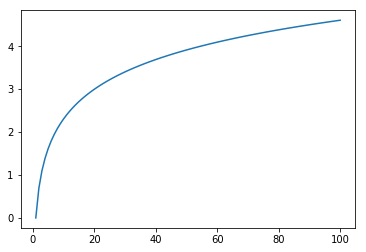

In [ ]:
import math
import matplotlib.pyplot as plt

x = np.arange(1, 101)

y = np.vectorize(math.log)(x)

plt.plot(x, y)
plt.show()

In [ ]:
y

array([0.        , 0.69314718, 1.09861229, 1.38629436, 1.60943791,
       1.79175947, 1.94591015, 2.07944154, 2.19722458, 2.30258509,
       2.39789527, 2.48490665, 2.56494936, 2.63905733, 2.7080502 ,
       2.77258872, 2.83321334, 2.89037176, 2.94443898, 2.99573227,
       3.04452244, 3.09104245, 3.13549422, 3.17805383, 3.21887582,
       3.25809654, 3.29583687, 3.33220451, 3.36729583, 3.40119738,
       3.4339872 , 3.4657359 , 3.49650756, 3.52636052, 3.55534806,
       3.58351894, 3.61091791, 3.63758616, 3.66356165, 3.68887945,
       3.71357207, 3.73766962, 3.76120012, 3.78418963, 3.80666249,
       3.8286414 , 3.8501476 , 3.87120101, 3.8918203 , 3.91202301,
       3.93182563, 3.95124372, 3.97029191, 3.98898405, 4.00733319,
       4.02535169, 4.04305127, 4.06044301, 4.07753744, 4.09434456,
       4.11087386, 4.12713439, 4.14313473, 4.15888308, 4.17438727,
       4.18965474, 4.20469262, 4.21950771, 4.2341065 , 4.24849524,
       4.26267988, 4.27666612, 4.29045944, 4.30406509, 4.31748

## Broadcasting [30 min]

#### Broadcasting is one of the most important and interesting concept in numpy


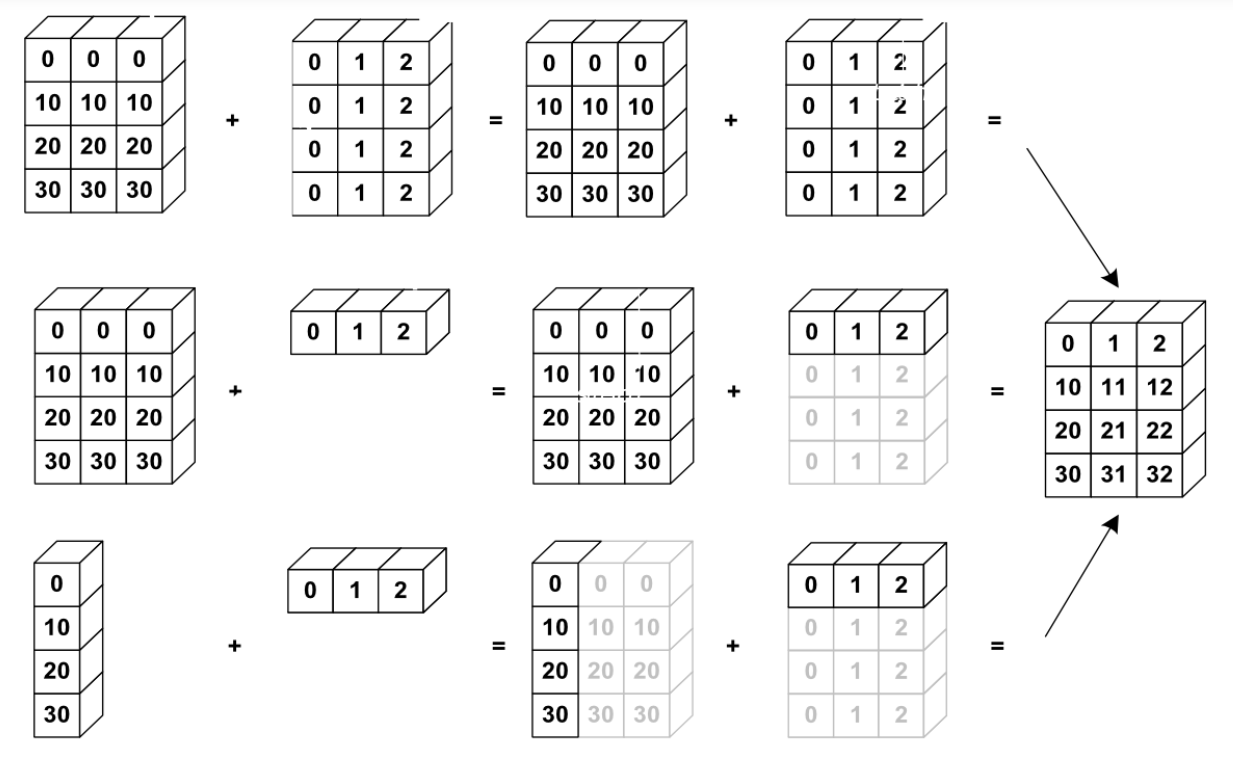

#### Case1:
You are given two 2D array

```
[[0,   0,  0],      [[0, 1, 2],
 [10, 10, 10], and   [0, 1, 2],
 [20, 20, 20],       [0, 1, 2],
 [30, 30, 30]]       [0, 1, 2]]

```
Shape of **first array** is **4x3**

Shape of **second array** is **4x3**.

Will addtion of these array be possible? Yes as the shape of these two array matches.

#### Let's create the array and see:

In [ ]:
a = np.tile(np.arange(0,40,10), (3,1))
a

array([[ 0, 10, 20, 30],
       [ 0, 10, 20, 30],
       [ 0, 10, 20, 30]])

**`np.tile` function is used to repeat the given array multiple times**

In [ ]:
np.tile(np.arange(0,40,10), (3,2))

array([[ 0, 10, 20, 30,  0, 10, 20, 30],
       [ 0, 10, 20, 30,  0, 10, 20, 30],
       [ 0, 10, 20, 30,  0, 10, 20, 30]])

Now, let's get back to example:

In [ ]:
a

array([[ 0, 10, 20, 30],
       [ 0, 10, 20, 30],
       [ 0, 10, 20, 30]])

In [ ]:
a = a.T

In [ ]:
a

array([[ 0,  0,  0],
       [10, 10, 10],
       [20, 20, 20],
       [30, 30, 30]])

In [ ]:
b = np.tile(np.arange(0,3), (4,1))

In [ ]:
b

array([[0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2]])

Let's add these two arrays:

In [ ]:
a + b

array([[ 0,  1,  2],
       [10, 11, 12],
       [20, 21, 22],
       [30, 31, 32]])

Text book case of element wise addition of two 2D arrays.

Here comes the interesting part:

#### Case2 :

Imagine a array like this:

```

[[0,   0,  0],     
 [10, 10, 10],  
 [20, 20, 20],       
 [30, 30, 30]]

```
I want to add the following array to it:

```
 [[0, 1, 2]]

```

Is it possible? **Yes!**

What broadcasting does is replicate the second array row wise 4 times to fit the size of first array.

Here both array have same number of columns

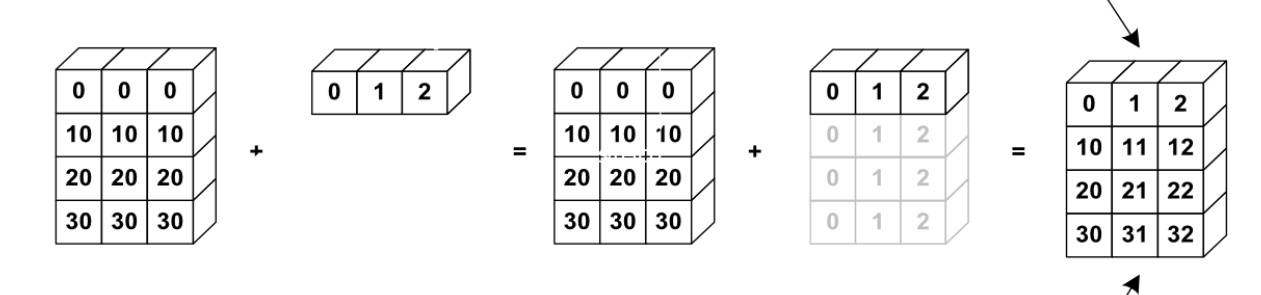

In [ ]:
a

array([[ 0,  0,  0],
       [10, 10, 10],
       [20, 20, 20],
       [30, 30, 30]])

In [ ]:
b = np.arange(0,3)
b

array([0, 1, 2])

In [ ]:
a + b

array([[ 0,  1,  2],
       [10, 11, 12],
       [20, 21, 22],
       [30, 31, 32]])

The **smaller array is broadcast across the larger array** so that they have **compatible shapes**.

Let's spice it up a litte bit more:

#### Case 3:

Imagine I have two array like this:

```
     [[0],
     [10],
     [20],
     [30]]

```
and

```
  [[0, 1, 2]]

```

i.e. one column matrix and one row matrix.

When we try to add these array up, broadcasting will replicate first array column wise 3 time and secord array row wise 4 times to match up the shape.

Let's try to add these two arrays:

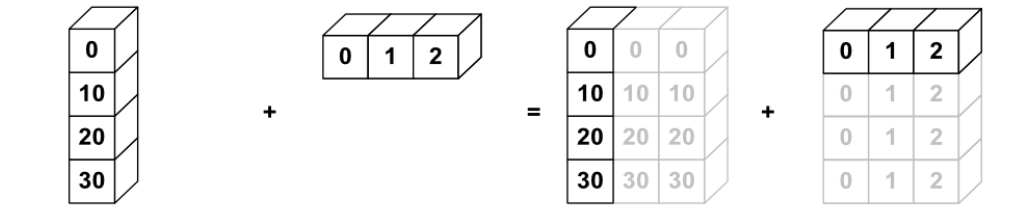

In [ ]:
a = np.arange(0,40,10)
a

array([ 0, 10, 20, 30])

This is a 1D row wise array, But we want this array colum wise? How do we do it ?
Reshape?

In [ ]:
a = a.reshape(4,1)
a

array([[ 0],
       [10],
       [20],
       [30]])

In [ ]:
b = np.arange(0,3)
b

array([0, 1, 2])

In [ ]:
a + b

array([[ 0,  1,  2],
       [10, 11, 12],
       [20, 21, 22],
       [30, 31, 32]])

#### Question: (for general broadcasting rules)

What will be the output of the following?
```
a = np.arange(8).reshape(2,4)
b = np.arange(16).reshape(4,4)

print(a*b)
```



In [ ]:
a = np.arange(8).reshape(2,4)
a

array([[0, 1, 2, 3],
       [4, 5, 6, 7]])

In [ ]:
b = np.arange(16).reshape(4,4)
b

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11],
       [12, 13, 14, 15]])

In [ ]:
a + b

ValueError: operands could not be broadcast together with shapes (2,4) (4,4) 

#### Why didn't it work?

To understand this, let's learn about some **General Broadcasting Rules**

When operating on two arrays, NumPy compares their shapes element-wise. It starts with the trailing (i.e. rightmost) dimensions and works its way left.

Two **dimensions** are compatible when:
1. they are equal, or
2. one of them is 1


If these conditions are not met, a **ValueError: operands could not be broadcast together exception is thrown, indicating that the arrays have incompatible shapes.**

In the above example, the shapes were (2,4) and (4,4).

First, it will compare the right most dimension (4) which are equal. Next, it will compare the left dimension i.e. 2 and 4. Both conditions fail here. They are neither equal nor one of them is 1. Hence, it threw an error while broadcasting.




#### Now, Let's take a look at few more examples



#### Question-1: What will be the output of this?
```
A = np.arange(1,10).reshape(3,3)
B = np.array([-1, 0, 1])
A * B
```

In [ ]:
A = np.arange(1,10).reshape(3,3)
A

array([[1, 2, 3],
       [4, 5, 6],
       [7, 8, 9]])

In [ ]:
B = np.array([-1, 0, 1])
B

array([-1,  0,  1])

In [ ]:
A * B

array([[-1,  0,  3],
       [-4,  0,  6],
       [-7,  0,  9]])

#### Why did `A * B` work in this case?

- `A` has 3 rows and 3 columns

- `B` is a 1-D vector with 3 elements

- So, **`B` gets broadcasted over `A` for each row of `A`**

#### We can perform other arithmetic operations as well with the help of Broadcasting



#### Question-2: What will be the result of this?
```
A = np.arange(1,10).reshape(3,3)
B = np.arange(3, 10, 3).reshape(3,1)
C = A + B
```

In [ ]:
A = np.arange(1,10).reshape(3,3)
A

array([[1, 2, 3],
       [4, 5, 6],
       [7, 8, 9]])

In [ ]:
B = np.arange(3, 10, 3).reshape(3,1)
B

array([[3],
       [6],
       [9]])

In [ ]:
C = A + B
np.round(C, 1)

array([[ 4,  5,  6],
       [10, 11, 12],
       [16, 17, 18]])

#### How did this `A + B` work?

- `A` has 3 rows and 3 columns

- `B` has 3 rows and 1 column ---> Its a column vector


- So, **`B` gets broadcasted on every column of `A`**

#### Quiz-3
```
A = np.arange(12).reshape(3, 4)
B = np.array([1, 2, 3])



What'll be the output of A + B ?


A. [[0, 1, 2, 3],
    [4, 5, 6, 7],
    [8, 9, 10, 11]]

B. Error

C. [[1, 2, 3, 4],
    [6, 7, 8, 9],
    [11,12,13,14]]
```

Answer: B (Error as neither rows nor columns are matching for it to be broadcasted)

In [ ]:
A = np.arange(12).reshape(3, 4)  # A is a 3x4 Matrix
A

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

In [ ]:
B = np.array([1, 2, 3])
B

array([1, 2, 3])

In [ ]:
A + B

ValueError: ignored

***

## Array Splitting and Merging

- We have up to now looked at methods to rearrange arrays.


- We also looked at how to extract subarrays using various indexing techniques.


- In addition to reshaping and selecting subarrays, it is often necessary to split arrays into smaller arrays or  merge arrays into bigger arrays,


- **For example**, when joining separately computed or measured data series into a **higher-dimensional array**, such as a matrix.

#### Numpy provides certain functions for the task of  splitting/stacking/merging of arrays

### Splitting
#### `np.split()`

- Splits an array into multiple sub-arrays as views


#### It takes an argument `indices_or_sections`

- If `indices_or_sections` is an **integer, n**, the array will be **divided into n equal arrays along axis**.

- If such a split is not possible, an error is raised.

- If `indices_or_sections` is a **1-D array of sorted integers**, the entries indicate **where along axis the array is split**.

- If an index **exceeds the dimension of the array along axis**, an **empty sub-array is returned** correspondingly.

In [ ]:
x = np.arange(9)
x

array([0, 1, 2, 3, 4, 5, 6, 7, 8])

In [ ]:
np.split(x, 3)

[array([0, 1, 2]), array([3, 4, 5]), array([6, 7, 8])]

In [ ]:
np.split(x, [3, 5, 6])

[array([0, 1, 2]), array([3, 4]), array([5]), array([6, 7, 8])]

#### `np.hsplit()`

- Splits an array into multiple sub-arrays **horizontally (column-wise)**.

In [ ]:
x = np.arange(16.0).reshape(4, 4)
x

array([[ 0.,  1.,  2.,  3.],
       [ 4.,  5.,  6.,  7.],
       [ 8.,  9., 10., 11.],
       [12., 13., 14., 15.]])

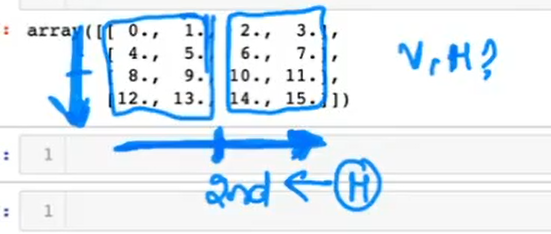

#### Think of it this way:

- There are 2 axis to a 2-D array
    1. **1st axis - Vertical axis**
    2. **2nd axis - Horizontal axis**

#### Along which axis are we splitting the array?

- The split we want happens across the **2nd axis (Horizontal axis)**


- That is why we use `hsplit()`


#### So, try to think in terms of "whether the operation is happening along vertical axis or horizontal axis"

- We are splitting the horizontal axis in this case

In [ ]:
np.hsplit(x, 2)

[array([[ 0.,  1.],
        [ 4.,  5.],
        [ 8.,  9.],
        [12., 13.]]), array([[ 2.,  3.],
        [ 6.,  7.],
        [10., 11.],
        [14., 15.]])]

In [ ]:
np.hsplit(x, np.array([3, 6]))

[array([[ 0.,  1.,  2.],
        [ 4.,  5.,  6.],
        [ 8.,  9., 10.],
        [12., 13., 14.]]), array([[ 3.],
        [ 7.],
        [11.],
        [15.]]), array([], shape=(4, 0), dtype=float64)]

#### `np.vsplit()`

- Splits an array into multiple sub-arrays **vertically (row-wise)**.

In [ ]:
x = np.arange(16.0).reshape(4, 4)
x

array([[ 0.,  1.,  2.,  3.],
       [ 4.,  5.,  6.,  7.],
       [ 8.,  9., 10., 11.],
       [12., 13., 14., 15.]])

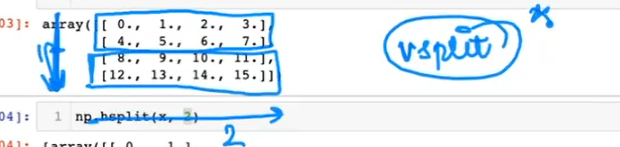

#### Now, along which axis are we splitting the array?

- The split we want happens across the **1st axis (Vertical axis)**


- That is why we use `vsplit()`


#### Again, always try to think in terms of "whether the operation is happening along vertical axis or horizontal axis"

- We are splitting the vertical axis in this case

In [ ]:
np.vsplit(x, 2)

[array([[0., 1., 2., 3.],
        [4., 5., 6., 7.]]), array([[ 8.,  9., 10., 11.],
        [12., 13., 14., 15.]])]

In [ ]:
np.vsplit(x, np.array([3]))

[array([[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11.]]), array([[12., 13., 14., 15.]])]

### Stacking
#### Let's say we have an array and we want to stack it like this:



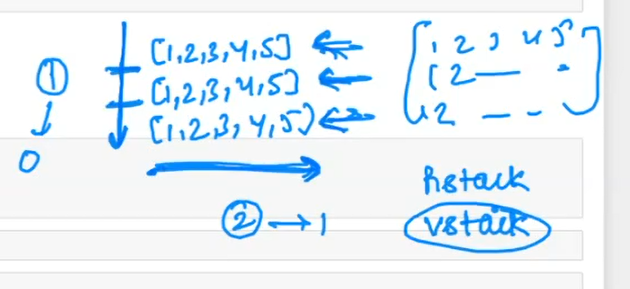

#### Will we use `vstack()` or `hstack()`?

#### Along which axis the operation is happening?

- Vertical axis

- So, we'll use `vstack()`

#### `np.vstack()`

- Stacks a list of arrays **vertically (along axis 0 or 1st axis)**


- For **example**, **given a list of row vectors, appends the rows to form a matrix**.

In [ ]:
data = np.arange(5)
data

array([0, 1, 2, 3, 4])

In [ ]:
np.vstack((data, data, data))

array([[0, 1, 2, 3, 4],
       [0, 1, 2, 3, 4],
       [0, 1, 2, 3, 4]])

#### Now, What if we want to stack the array like this?

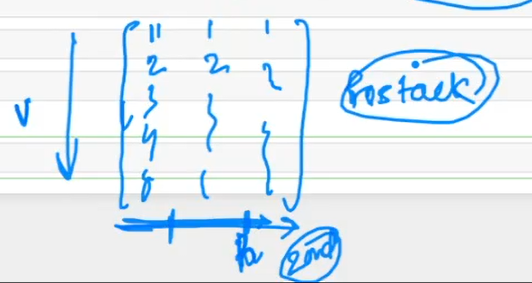

- Operation or **change is happening along horizontal axis**

- So, we'll use `hstack()`

#### `np.hstack()`

- Stacks a list of arrays horizontally (along axis 1)

- For **example**, **given a list of column vectors, appends the columns to form a matrix**.

In [ ]:
data = np.arange(5).reshape(5,1)
data

array([[0],
       [1],
       [2],
       [3],
       [4]])

In [ ]:
np.hstack((data, data, data))

array([[0, 0, 0],
       [1, 1, 1],
       [2, 2, 2],
       [3, 3, 3],
       [4, 4, 4]])

#### Quiz-4

What will be the output of the following code snippet?
```
a = np.array([1, 2, 3])

b = np.array([4, 5, 6])

print(np.hstack((a, b)))

```

```
A. [[1,2,3],
    [4,5,6]]

B. Error

C. [[1, 4],
    [2, 5],
    [3, 6]]

D. [1,2,3,4,5,6]

```
Ans: **D**

Explanation:
Since **both are 1-D row arrays**, `hstack()` formed a **single row array as result**



#### Question-3: Now, What will be the output of this?

```
a = np.array([[1], [2], [3]])
b = np.array([[4], [5], [6]])
np.hstack((a, b))
```


In [ ]:
a = np.array([[1], [2], [3]])
a

array([[1],
       [2],
       [3]])

In [ ]:
b = np.array([[4], [5], [6]])
b

array([[4],
       [5],
       [6]])

In [ ]:
np.hstack((a, b))

array([[1, 4],
       [2, 5],
       [3, 6]])

#### This time both `a` and `b` are column vectors

- So, the stacking of `a` and `b` along horizontal axis is more clearly visible

#### Quiz-5

What will be the output of following code?
```
a = np.array([[1], [2], [3]])
b = np.array([[4], [5], [6]])
np.vstack((a, b))
```

**Ans. C**

A. ```array([1, 2, 3, 4, 5, 6])```
       
B. ```array([[1, 4],
          [2, 5],
          [3, 6]])```
       
C. ```array([[1],
          [2],
          [3],
          [4],
          [5],
          [6]])```

D. Error

In [ ]:
a = np.array([[1], [2], [3]])
a

array([[1],
       [2],
       [3]])

In [ ]:
b = np.array([[4], [5], [6]])
b

array([[4],
       [5],
       [6]])

In [ ]:
np.vstack((a, b))

array([[1],
       [2],
       [3],
       [4],
       [5],
       [6]])

#### The stacking happens along vertical axis

#### Now, Let's look at a more generalized way of stacking arrays

### `np.concatenate()`

- Creates a new array by appending arrays after each other, along a given axis

- Provides similar functionality, but it takes a **keyword argument `axis`** that specifies the **axis along which the arrays are to be concatenated**.

#### Input array to `concatenate()` needs to be of dimensions atleast equal to the dimensions of output array

In [ ]:
z = np.array([[2, 4]])
z

array([[2, 4]])

In [ ]:
z.ndim

2

In [ ]:
zz = np.concatenate([z, z], axis=0)
zz

array([[2, 4],
       [2, 4]])

In [ ]:
zz = np.concatenate([z, z], axis=1)
zz

array([[2, 4, 2, 4]])

#### Let's look at a few more examples using `np.concatenate()`

#### Question-4: What will be the output of this?
```
a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6]])
np.concatenate((a, b), axis=0)
```

In [ ]:
a = np.array([[1, 2], [3, 4]])
a

array([[1, 2],
       [3, 4]])

In [ ]:
b = np.array([[5, 6]])
b

array([[5, 6]])

In [ ]:
np.concatenate((a, b), axis=0)

array([[1, 2],
       [3, 4],
       [5, 6]])

#### Now, How did it work?

- Dimensions of `a` is $2\times2$

#### What is the dimensions of `b` ?

- 1-D array ?? - **NO**

- Look carefully!!

- **`b` is a 2-D array of dimensions $1\times2$**

#### `axis = 0` ---> It's a vertical axis

- So, **changes will happen along vertical axis**

- So, **`b` gets concatenated below `a`**

#### Let's look at some question:



#### Quiz -6 : What will be the result of this concatenation operation?

```
a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6]])
np.concatenate((a, b.T), axis=1)
```

```
A. [[1, 2],
    [3, 4],
    [5, 6]]

B. [[1, 2, 5],
    [3, 4, 6]]

C. Error


```
Ans: B

In [ ]:
a = np.array([[1, 2], [3, 4]])
a

array([[1, 2],
       [3, 4]])

In [ ]:
b = np.array([[5, 6]])
b

array([[5, 6]])

In [ ]:
np.concatenate((a, b.T), axis=1)

array([[1, 2, 5],
       [3, 4, 6]])

#### What happened here?

- **Dimensions of `a`** is again $2\times2$

- **Dimensions of `b`** is again $1\times2$

- So, **Dimensions of `b.T`** will be $2\times1$

#### This time, **`axis = 1`** ---> Changes will happen along horizontal axis

- So, **`b.T` gets concatenated horizontally to `a`**

#### Now, What if we do NOT provide an axis along which to concatenate?

#### For example:

In [ ]:
a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6]])
np.concatenate((a, b), axis=None)

array([1, 2, 3, 4, 5, 6])

#### Can you see what happened here?

- When we **don't specify the axis (`axis=None`)**, `np.concatenate()` **flattens the arrays and concatenates them as 1-D row array**

***

## Views vs Copies (Shallow vs Deep Copy) [15 min]

- Numpy **manages memory very efficiently**


- Which makes it really **useful while dealing with large datasets**


#### But how does it manage memory so efficiently?

- Let's create some arrays to understand what's happening in memory while using Numpy

In [ ]:
# We'll create np array

a = np.arange(4)
a

array([0, 1, 2, 3])

In [ ]:
# Reshape array `a` and store in b

b = a.reshape(2, 2)
b

array([[0, 1],
       [2, 3]])

#### Now we will make some changes to our original array `a`

In [ ]:
a[0] = 100
a

array([100,   1,   2,   3])

#### Let's see what happens to our array `b`

In [ ]:
b

array([[100,   1],
       [  2,   3]])

#### Surprise Surprise!!

- Array **`b` got automatically updated**

### This is an example of Numpy using "Shallow Copy" of data

#### Now, What happens here?

- Numpy **re-uses data** as much as possible **instead of duplicating** it


- This helps Numpy to be efficient


#### When we created `b = a.reshape(2, 2)`

- Numpy **did NOT make a copy of `a` to store in `b`**, as we can clearly see


- It is **using the same data as in `a`**


- It **just looks different (reshaped)** in `b`


- That is why, **any changes in `a` automatically gets reflected in `b`**


#### How data is stored using Numpy?

- Variable **does NOT directly point to data** stored in memory


- There is something called **Header** in-between


### What does Header do?

- **Variable points to header** and **header points to data** stored in memory


- Header stores **information about data** - called **Metadata**


#### `a` is pointing to Metadata about our data `[0, 1, 2, 3]`, which may include:

- **How many values** we have --> 4


- What is the **Data Type** of data --> `int`


- What's the **Shape** --> `(4,)`


#### When we do `b = a.reshape(2, 2)`

- Numpy **does NOT duplicate the data** pointed to by `a`


- It **uses the same data**


- And **create a New header for `b`** that **points to the same data** as pointed to by `a`


#### `b` points to a new Header having different values of Metadata of the same data:

- **Number of values** --> 4

- **Data Type** --> `int`

- **Shape** --> `(2, 2)`


#### That is why:

- When data is accessed using `a`, it gives data in shape `(4,)`

- And when data is accessed using `b`, it gives same data in shape `(2, 2)`



#### This helps Numpy to save time and space - Making it efficient

### Now, Let's see an example where Numpy will create a "Deep Copy" of data

#### Now, What if we do this?

In [ ]:
a = np.arange(4)
a

array([0, 1, 2, 3])

In [ ]:
# Create `c`

c = a + 2
c

array([2, 3, 4, 5])

In [ ]:
# We make changes in a

a[0] = 100
a

array([100,   1,   2,   3])

In [ ]:
c

array([2, 3, 4, 5])

#### As we can see, `c` did not get affected on changing `a`

- Because it is an operation


- A more **permanent change in data**


- So, Numpy **had to create a separate copy for `c`** - i.e., **deep copy of array `a` for array `c`**


### Conclusion:

- Numpy is able to **use same data** for **simpler operations** like **reshape** ---> **Shallow Copy**


- It creates a **copy of data** where operations make **more permanent changes** to data ---> **Deep Copy**


#### Be careful about this while writing code using Numpy

#### Is there a way to check whether two arrays are sharing memory or not? Yes, there is

`np.shares_memory()` function to the rescue!!


In [ ]:
a= np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [ ]:
b = a[::2]
b

array([0, 2, 4, 6, 8])

In [ ]:
np.shares_memory(a,b)

True

In [ ]:
b[0] = 2
b

array([2, 2, 4, 6, 8])

In [ ]:
a

array([2, 1, 2, 3, 4, 5, 6, 7, 8, 9])

#### Notice how change in b also changed the value in array a

Let's check with deep copy

In [ ]:
a

array([2, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [ ]:
b = a +2

In [ ]:
np.shares_memory(a,b)

False

#### Quiz-7
```

a = [0,1,2,3,4,5]
b = a[a%1 == 0]

b[0] = 10

a[:2] = ?

a. [0,1]
b.[0,1,2]
c. [10,1]
d. [10,1,2]

```
Ans: A (masking creates new memory)

In [ ]:
a = np.arange(6)
b = a[a%1 == 0]

In [ ]:
a

array([0, 1, 2, 3, 4, 5])

In [ ]:
b

array([0, 1, 2, 3, 4, 5])

In [ ]:
b[0] = 10

In [ ]:
a[:2]

array([0, 1])

***

## 3 Dimensional Arrays

### Vectors, Matrix and Tensors

1. **Vector** ---> **1-Dimensional** Array
2. **Matrix** ---> **2-Dimensional** Array
3. **Tensor** ---> **3 and above Dimensional** Array


#### `Tensor` is a general term we use

- Tensor can also be less than 3D


- **2D Tensor** is called a **Matrix**
- **1D Tensor** is called a **Vector**

In [ ]:
B = np.arange(24).reshape(2, 3, 4)
B

array([[[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]],

       [[12, 13, 14, 15],
        [16, 17, 18, 19],
        [20, 21, 22, 23]]])

#### Now, What is happening here?

#### Question: How many dimensions `B` has?
- 3


- It's a **3-dimensional tensor**


#### How is `reshape(2, 3, 4)` working?

- If you see, it is giving 2 matrices


- Each matrix has 3 rows and 4 columns


#### So, that's how reshape() is interpreted for 3D

- **1st argument** gives **depth** (No. of Matrices)


- **2nd agrument** gives **no. of rows** in each depth


- **3rd agrument** gives **no. of columns** in each depth


#### How can I get just the whole of 1st Matrix?

In [ ]:
B[0]

#### Question-5: What value will I get if I do `B[0, 0, 0]`?

In [ ]:
B[0, 0, 0]

In [ ]:
#### Question: What value will I get if I do `B[1, 1, 1]`?
B[1, 1, 1]

# It looks at Matrix 1, that is, 2nd Matrix (Not Matrix 0)
# Then it looks at row 1 of matrix 1
# Then it looks at column 1 of row 1 of matrix 1

#### We can also Slicing in 3-Dimensions

- Works same as in 2-D matrices

## Use Case: Image Manipulation using Numpy [40 min]

- By now, you already have an idea that Numpy is an amazing open-source Python library for **data manipulation** and **scientific computing**.


- It is used in the domain of **linear algebra**, Fourier transforms, **matrices**, and the **data science field**.


- **NumPy arrays are way faster than Python Lists**.


#### Do you know Numpy can also be used for Image Processing?

- The fundamental idea is that we know **images are made up of Numpy `ndarrays`**.


- So we can **manipulate these arrays and play with images**.


- This use case is to give you a broad overview of **Numpy for Image Processing.**

#### Make sure the required libraries are imported

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#### Now, we'll see how we can play with images using Numpy

## Opening an Image [5 min]

- Well, to play with an image, we first need to open it

#### But, How can we open an image in our code?

- To open an image, we will use the `matplotlib` library to read and show images.


- We will cover all the functionalities of `matplotlib` in detail in visualization lecture.


- For this use case, just know that it uses an image module for working with images.


- It offers two useful methods **`imread()` and `imshow()`**.


**`imread()` – to read the images**

**`imshow()` – to display the images**


#### Now, Let's go ahead and load our image

#### Drive link for the image:

Download the image `fruits.jpg` from here: https://drive.google.com/file/d/1lHPQUi3wdB6HxN-SNJSBQXK7Z0y0wf32/view?usp=sharing

and place it in your current working directory

#### Let's download the images first

In [ ]:
#fruits image
!gdown 17tYTDPBU5hpby9t0kGd7w_-zBsbY7sEd

In [ ]:
#emma stone image
!gdown 1o-8yqdTM7cfz_mAaNCi2nH0urFu7pcqI

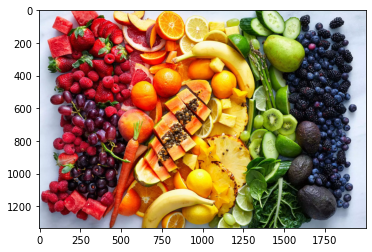

In [ ]:
img = np.array(plt.imread('fruits.png'))
plt.imshow(img)

## Details of an Image [1 min]

#### What do you think are the dimensions and shape of this image?

We will see what is the **dimension and shape of this image**, using the **`Image.ndim`** and **`Image.shape`** properties.

In [ ]:
print('# of dims: ',img.ndim)     # dimension of an image
print('Img shape: ',img.shape)    # shape of an image

# of dims:  3
Img shape:  (1333, 2000, 3)


#### How come our 2-D image has 3 dimensions?

- **Coloured images have a 3rd dimension for depth or RGB colour channel**


- Here, the **depth is 3**


- But we will come to what RGB colour channels are in a bit


#### First, Let's understand something peculiar happening here with the `shape` of image

#### Do you see something different happening here when we check the `shape` of image?

- When we discussed **3-D Arrays**, we saw that **depth was the first element of the `shape` tuple**


- But when we are loading an image using **matplotlib and getting its 3-D array**, we see that **depth is the last element of the `shape` tuple**


#### Why is there a difference b/w normal np array and the np array generated from Matplotlib in terms of where the depth part of `shape` appears?

- This is how `matplotlib` reads the image


- It **reads the depth values (R, G and B values) of each pixel one by one** and stacks them one after the other


#### The shape of imge we read is:  (1333, 2000, 3)

- `matplotlib` **first reads that each plane has $1333\times2000$ pixels**


- Then, it **reads depth values (R, G and B values) of each pixel and place the values in 3 separate planes**


- That is why **depth is the last element of `shape` tuple in np array generated from an image read by `matplotlib`**


- Whereas in a **normal np array, depth is the first element of `shape` tuple**


#### Now, What are these RGB channels and How can we visualize them?

## Visualizing RGB Channels [10 min]

We can split the image into each RGB color channels using only Numpy

#### But, What exactly RGB values are?

- These are values of each pixel of an image


- Each pixel is made up of **3 components/channels** - **Red, Green, Blue** - which form RGB values


- Coloured images are usually stored as 3-dimensional arrays of **8-bit unsigned integers**


- So, the range of values that each channel of a pixel can take is $0$ to $2^8 - 1$


- That is, each pixel's each channel, R, G and B can range from **0 to 255**


#### Each pixel has these 3 values which combined together forms the colour that the pixel represents

- So, a pixel **[255, 0, 0 ]** will be **RED** in colour

- A pixel **[0, 255, 0]** will be **GREEN** in colour

- A pixel **[0, 0, 255]** will be **BLUE** in colour


#### Question: What will be the colour of pixel [0, 0, 0]?

- Black


#### Question: What will be the colour of pixel [255, 255, 255]?

- White


#### Now, Let's separate the R, G, B channels in our image:

- We'll make use of **slicing of arrays**

- For **RED** channel, we'll **set values of GREEN and BLUE to 0**

- Similarly, for GREEN channel, we'll set values of RED and BLUE to 0

- ... and same for BLUE channel

In [ ]:
img = np.array(plt.imread('fruits.png'))

img_R, img_G, img_B = img.copy(), img.copy(), img.copy()

img_R[:, :, (1, 2)] = 0
img_G[:, :, (0, 2)] = 0
img_B[:, :, (0, 1)] = 0

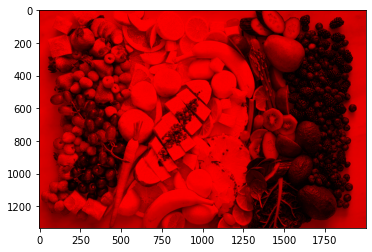

In [ ]:
plt.imshow(img_R)

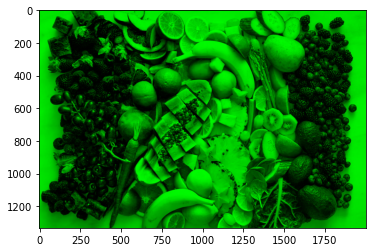

In [ ]:
plt.imshow(img_G)

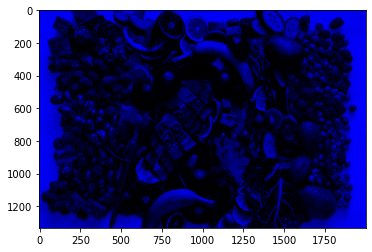

In [ ]:
plt.imshow(img_B)

### Converting Image to Gray Scale

- We can also convert a coloured image to gray scale using Numpy

#### But, What exactly is a Gray Scale image?

- A gray scale image is one which **only has 1 channel** - Either R or G or B

- We can get images having a single channel using the concept of **slicing in Numpy**


#### How will we slice the image array to get images having single channel

- We need all rows and columns, but we only need 1 channel at a time

- **RED channel** is at **depth index 0**
- **GREEN channel** is at **depth index 1**
- **BLUE channel** is at **depth index 2**


#### For example, to get grayscale image only for RED channel, we have to do something like:

`image[:, :, 0]`

- `image[:, :, 0]` means get **all rows, all columns**, and the **first (at index 0) color channel**, which is the **RED channel**.

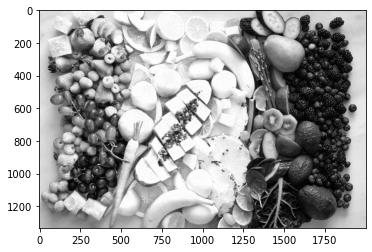

In [ ]:
img = np.array(plt.imread('fruits.png'))

img_R_grayscale = img[:,:,0]
plt.imshow(img_R_grayscale, cmap='gray')

# Matplotlib uses a colormap by default when plotting a single channel.
# So, we have to specify `cmap='gray' within the `imshow() function

- As you can see the **areas with RED colour in original image are more bright in gray scale image** with only R channel

- We can use this information to indentify where a **colour channel is more concentrated within the image**

- Because the area with that colour channel will **brighten up in gray scale image**


#### Let's check the shape of this gray scale image with only RED channel

In [ ]:
img_R_grayscale.shape

(1333, 2000)

#### As you can notice, its a 2-D array now

- Because **depth of R, G, B has been removed**

- It **only consists of 1 channel** - R channel


#### Question: Now, How can we see Gray Scale images having only GREEN and only BLUE channel?
#### Question: What will be the image slicing to get gray scale image having only GREEN and only BLUE channel?

**Remember? GREEN channel is at depth index 1 and BLUE channel is at depth index 2**

- **`image[:, :, 1]`** ---> **Gray Scale image** with **only GREEN** channel

- **`image[:, :, 2]`** ---> **Gray Scale image** with **only BLUE** channel

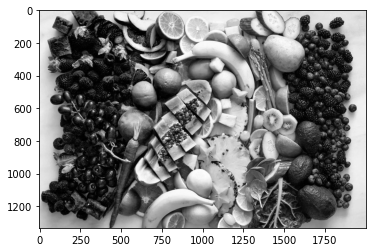

In [ ]:
img_G_grayscale = img[:,:,1]
plt.imshow(img_G_grayscale, cmap='gray')

#### Do you see the difference b/w `img_R_grayscale` and `img_G_grayscale`?

- Brightness of different areas is different


- In `img_R_grayscale`, the red areas are more bright

- In `img_G_grayscale`, the green areas are more bright

#### Now, Let's compute gray scale image with only BLUE channel:

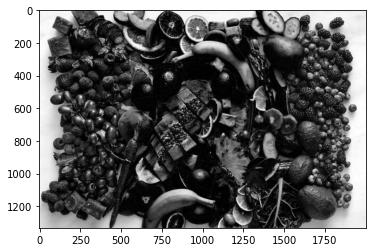

In [ ]:
img_B_grayscale = img[:,:,2]
plt.imshow(img_B_grayscale, cmap='gray')

Now, you can clearly see the differences b/w gray scale images having each channel separately

## Rotating an Image (Transpose the Numpy Array) [5 min]

#### Now, What if we want to rotate the image?

- Remember **image is a Numpy array**


- **Rotating the image means transposing the array**


#### For this, we'll use the `np.transpose()` function in numpy

#### Now, Let's understand `np.transpose()` function first

- It takes 2 arguments


**1st argument** is obviously the **array that we want to transpose (image array in our case)**


**2nd argument is `axes`**
- Its a **tuple or list of ints**

- It contains a **permutation of [0,1,..,N-1] where N is the number of axes of array**

#### Now, our image array has 3 axes (3 dimensions) ---> 0th, 1st and 2nd

- We specify how we want to transpose the array by giving an **order of these axes inside the tuple**

    - **Vertical axis (Row axis) is 0th axis**
    - **Horizontal axis (Column axis) is 1st axis**
    - **Depth axis is 2nd axis**


- **In order to rotate the image, we want to transpose the array**


- That is, we want to **transpose rows into columns and columns into rows**


- So, we want to **interchange the order of row and column axis** ---> **interchange order of 0th and 1st axis**


- We **don't want to change the depth axis (2nd axis)** ---> So, it will **remain at its original order position**


Now, the **order of axes in orginal image is `(0, 1, 2)`**

#### What will be the order of axes rotated image or transposed array?

- The **order of axes in rotated image will be `(1, 0, 2)`**


- **Order (Position) of 0th and 1st column is interchanged**


#### Let's see it in action:

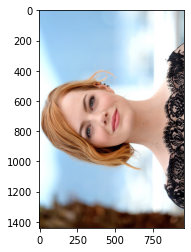

In [ ]:
img = np.array(plt.imread('emma_stone.jpg'))
img_rotated = np.transpose(img, (1,0,2))
plt.imshow(img_rotated)

#### As you can see:

- We obtained the **rotated image by transposing the np array**

## Saving Image as `ndarray` [1 min]

#### Now, How can we save `ndarray` as Image?

To save a `ndarray` as an image, we can use `matplotlib`'s `plt.imsave()` method.


- **1st agrument** ---> We provide the path and name of file we want to save the image as


- **2nd agrument** ---> We provide the image we want to save


#### Let's save the cropped face image we obtained previously

In [ ]:
path = 'emma_face.jpg'
plt.imsave(path, img_rotated)

#### Now, if you go and check your current working directory, image would have been saved by the name `emma_face.jpg`

***
This way we can do many interesting things with Images using just Numpy, without the use of image processing libraries like OpenCV.

### Final Q&A for Today's Lecture